# Social Media Engagement Analysis: Exploratory Data Visualization
**College Data Visualization (DV) Project**  
**Task Phase**: Milestone 3 — Exploratory Data Visualization  
**Dataset**: Cleaned Social Media Engagement Dataset (`data/processed/social_media_engagement_cleaned.csv`)  
**Author**: Data Analytics & Visualization Team  
**Objective**: Conduct systematic exploratory visualization across key dimensions (platforms, metrics, countries, time series, sentiment, and distributions) to answer meaningful research questions without fabricating unavailable data.


## 1. Environment Setup & Cleaned Dataset Ingestion
We load the validated, cleaned dataset produced in Milestone 2 from `data/processed/social_media_engagement_cleaned.csv` using relative paths.
The original raw dataset remains untouched.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

# Relative path resolution (compatible from workspace root or notebooks/ directory)
csv_path = os.path.join('data', 'processed', 'social_media_engagement_cleaned.csv') if os.path.exists(os.path.join('data', 'processed', 'social_media_engagement_cleaned.csv')) else os.path.join('..', 'data', 'processed', 'social_media_engagement_cleaned.csv')
figures_dir = os.path.join('reports', 'figures') if os.path.exists('reports') else os.path.join('..', 'reports', 'figures')
os.makedirs(figures_dir, exist_ok=True)

print(f"Loading cleaned dataset from: {csv_path}")
df = pd.read_csv(csv_path)

# Ensure proper data types
df['timestamp'] = pd.to_datetime(df['timestamp'])

print(f"Dataset successfully loaded: {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head(3)


Loading cleaned dataset from: data\processed\social_media_engagement_cleaned.csv
Dataset successfully loaded: 2,200 rows and 20 columns.


## 2. Analytical Scope & Missing Data Policy
### Data & Calculation Rules:
1. **No Data Fabrication**: Views, impressions, state/region, and content type are strictly absent from the dataset and are not invented.
2. **Missing Engagement Handling**: Total engagement is calculated strictly as $\text{likes} + \text{retweets\_shares} + \text{comments}$. If `likes` or `comments` is missing, `total_engagement` is `<NA>` (52 records). When calculating platform, country, or hourly averages, these 52 unrecorded records are excluded pairwise rather than assumed to be zero.
3. **Missing Country Handling**: 66 posts with `country == 'Unknown'` are retained for platform, temporal, and sentiment analyses, but explicitly excluded from country-level comparisons.
4. **Missing Sentiment Handling**: 33 posts with missing sentiment are excluded from sentiment breakdowns.
5. **Outlier Retention**: Authentic high-engagement viral posts are preserved to avoid suppressing natural right-skewed social media dynamics.
6. **Sample Size Transparency**: Post counts ($N$) are explicitly displayed alongside averages to avoid misleading comparisons across platforms and countries with unequal observation volumes.


In [2]:
# Verify key dimensions and missing value status before plotting
print("=== DATASET PROFILE SUMMARY ===")
print(f"Total Unique Posts: {len(df):,}")
print(f"Platforms Represented: {df['platform'].nunique()} {df['platform'].unique().tolist()}")
print(f"Countries Represented: {df['country'].nunique() - 1} known + 'Unknown'")
print(f"Date Span: {df['timestamp'].min().strftime('%Y-%m-%d')} to {df['timestamp'].max().strftime('%Y-%m-%d')} ({df['month_year'].nunique()} months)")
print(f"Valid Total Engagement Count: {df['total_engagement'].notna().sum():,} (Missing: {df['total_engagement'].isna().sum()})")
print(f"Valid Sentiment Count:        {df['sentiment'].notna().sum():,} (Missing: {df['sentiment'].isna().sum()})")


=== DATASET PROFILE SUMMARY ===
Total Unique Posts: 2,200
Platforms Represented: 5 ['TikTok', 'Facebook', 'Instagram', 'LinkedIn', 'Twitter']
Countries Represented: 12 known + 'Unknown'
Date Span: 2023-01-01 to 2024-12-31 (24 months)
Valid Total Engagement Count: 2,148 (Missing: 52)
Valid Sentiment Count:        2,167 (Missing: 33)


## 3. Visualization 1: Platform Comparison — Average Total Engagement
### Research Question:
* **Which social media platforms generate the highest average total engagement per post?**

### Visual Encoding & Rationale:
* **Chart Type**: Sorted Vertical Bar Chart.
* **Why Appropriate**: Bar charts provide discrete categorical comparisons with length encoding aligned to a common baseline, which human perception decodes with high precision.
* **Misleading Comparison Safeguard**: Post counts ($N$) are directly annotated above each bar to ensure viewers interpret averages in the context of varying sample sizes (e.g., LinkedIn $N=116$ vs Twitter $N=712$).
* **Missing Value Handling**: Evaluated strictly on the 2,148 records where `total_engagement` is non-null.


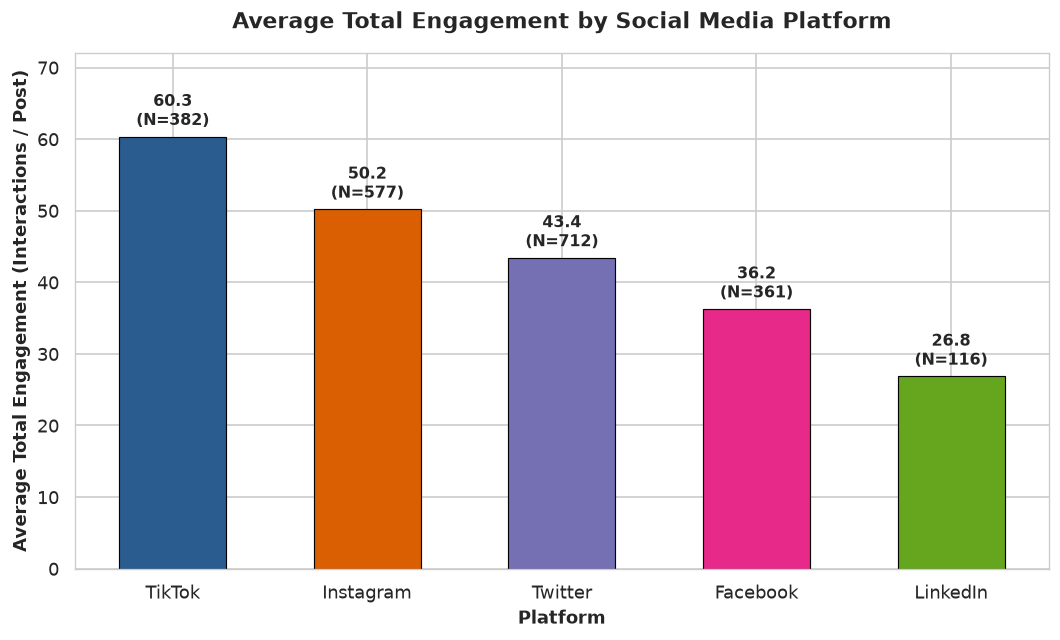

Platform Engagement Summary Table:
 platform  Mean_Engagement  Median_Engagement  Valid_Posts  Std_Dev
   TikTok            60.32               56.0          382    24.00
Instagram            50.18               46.0          577    21.18
  Twitter            43.39               40.0          712    19.16
 Facebook            36.24               34.0          361    15.89
 LinkedIn            26.84               24.5          116    11.64


In [3]:
# 1. Platform Comparison Calculation
p_order = ['TikTok', 'Instagram', 'Twitter', 'Facebook', 'LinkedIn']
platform_summary = df.groupby('platform')['total_engagement'].agg(
    Mean_Engagement='mean',
    Median_Engagement='median',
    Valid_Posts='count',
    Std_Dev='std'
).loc[p_order].reset_index()

print("Platform Engagement Summary Table:")
print(platform_summary.round(2).to_string(index=False))

# Plotting
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ['#2b5c8f', '#d95f02', '#7570b3', '#e7298a', '#66a61e']
bars = ax.bar(
    platform_summary['platform'],
    platform_summary['Mean_Engagement'],
    color=colors,
    width=0.55,
    edgecolor='black',
    linewidth=0.7
)

# Annotate values and sample sizes
for bar, count in zip(bars, platform_summary['Valid_Posts']):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.9,
            f'{h:.1f}\n(N={count})',
            ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax.set_title("Average Total Engagement by Social Media Platform", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Platform", fontsize=11, fontweight='bold')
ax.set_ylabel("Average Total Engagement (Interactions / Post)", fontsize=11, fontweight='bold')
ax.set_ylim(0, 72)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "01_platform_comparison.png"), dpi=200)
plt.show()


### Interpretation:
1. **TikTok** achieves the highest average total engagement (**60.3 interactions per post**), outperforming all other networks.
2. **Instagram** follows in second place with an average of **50.2 interactions per post**.
3. **Twitter** and **Facebook** occupy intermediate tiers at **43.4** and **36.2 interactions per post**, respectively.
4. **LinkedIn** records the lowest average engagement at **26.8 interactions per post**.

### Limitations:
* **Sample Size Disparity**: Twitter has over 6 times the sample volume ($N=712$ valid posts) of LinkedIn ($N=116$).
* **Absence of Reach Data**: Because impressions and video views are not available, we cannot distinguish whether TikTok's higher engagement stems from superior algorithmic reach or higher user interaction density.


## 4. Visualization 2: Engagement Components by Platform
### Research Question:
* **How do the individual constituent interaction types (likes, comments, and retweets/shares) compare across platforms?**

### Visual Encoding & Rationale:
* **Chart Type**: Grouped (Clustered) Bar Chart.
* **Why Appropriate**: Allows side-by-side decomposition of multiple continuous variables across categorical groups, highlighting both within-platform metric proportions and across-platform metric differences.
* **Missing Value Handling**: Means are computed pairwise across non-null records for each constituent metric (`likes.dropna()`, `retweets_shares.dropna()`, `comments.dropna()`).


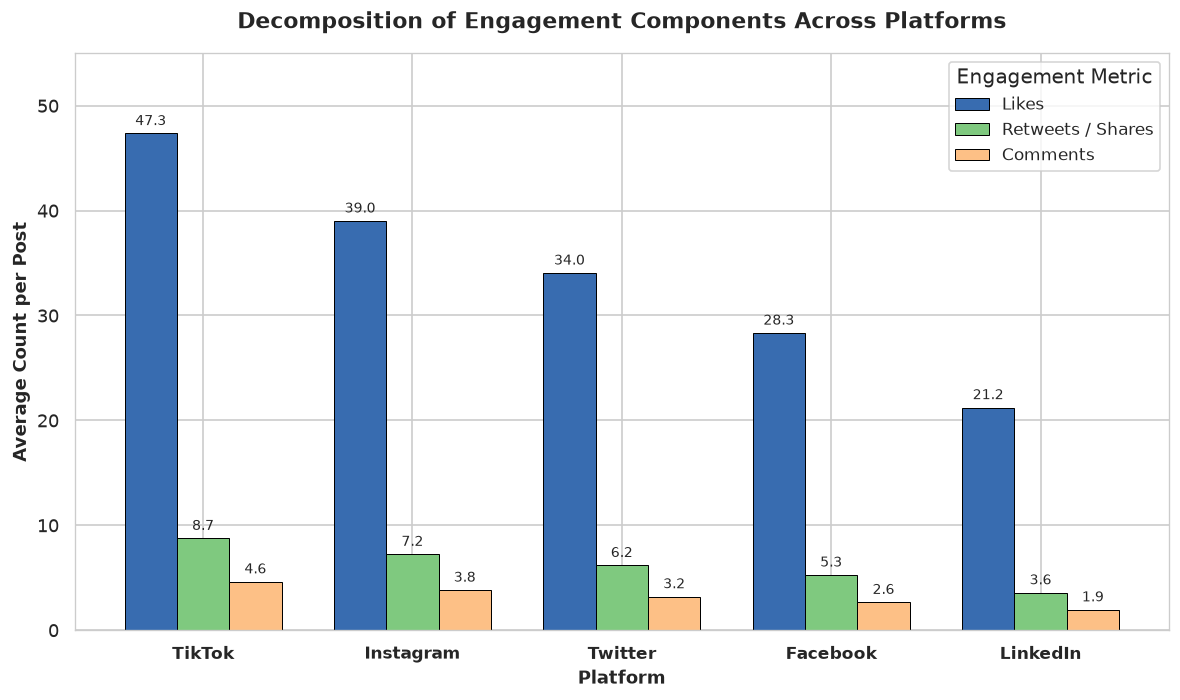

Engagement Components Summary Table (Averages):
 platform  likes  retweets_shares  comments
   TikTok  47.35             8.75      4.61
Instagram  39.01             7.24      3.81
  Twitter  34.04             6.17      3.19
 Facebook  28.32             5.25      2.65
 LinkedIn  21.22             3.56      1.94


In [4]:
# 2. Component Decomposition Calculation
comp_summary = df.groupby('platform')[['likes', 'retweets_shares', 'comments']].mean().loc[p_order].reset_index()

print("Engagement Components Summary Table (Averages):")
print(comp_summary.round(2).to_string(index=False))

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(p_order))
width = 0.25

ax.bar(x - width, comp_summary['likes'], width, label='Likes', color='#386cb0', edgecolor='black', linewidth=0.6)
ax.bar(x, comp_summary['retweets_shares'], width, label='Retweets / Shares', color='#7fc97f', edgecolor='black', linewidth=0.6)
ax.bar(x + width, comp_summary['comments'], width, label='Comments', color='#fdc086', edgecolor='black', linewidth=0.6)

ax.set_title("Decomposition of Engagement Components Across Platforms", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Platform", fontsize=11, fontweight='bold')
ax.set_ylabel("Average Count per Post", fontsize=11, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(p_order, fontsize=10, fontweight='bold')
ax.legend(title="Engagement Metric", frameon=True, fontsize=10)
ax.set_ylim(0, 55)

# Value labels on bars
for i in range(len(p_order)):
    ax.text(x[i] - width, comp_summary.loc[i, 'likes'] + 0.8, f"{comp_summary.loc[i, 'likes']:.1f}", ha='center', fontsize=8.5)
    ax.text(x[i], comp_summary.loc[i, 'retweets_shares'] + 0.8, f"{comp_summary.loc[i, 'retweets_shares']:.1f}", ha='center', fontsize=8.5)
    ax.text(x[i] + width, comp_summary.loc[i, 'comments'] + 0.8, f"{comp_summary.loc[i, 'comments']:.1f}", ha='center', fontsize=8.5)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "02_engagement_components.png"), dpi=200)
plt.show()


### Interpretation:
1. **Universal Like Dominance**: On every platform, likes constitute the vast majority (>75%) of total engagement volume.
2. **Shares vs. Comments**: Across all networks, shares/retweets consistently outnumber comments by roughly 1.8x to 2x (e.g., TikTok averages 8.7 shares vs. 4.6 comments; Twitter averages 6.2 shares vs. 3.2 comments).
3. **Platform-Wide Superiority**: TikTok leads across all three individual components (47.3 likes, 8.7 shares, 4.6 comments), followed in exact hierarchy by Instagram, Twitter, Facebook, and LinkedIn.

### Limitations:
* Comments represent a higher-friction user action than double-tapping a like, meaning a 1:1 numerical comparison understates the qualitative significance of comment conversations.


## 5. Visualization 3: Geographic Comparison — Country-Level Engagement
### Research Question:
* **Which countries exhibit the highest average post engagement, and how does engagement vary geographically?**

### Visual Encoding & Rationale:
* **Chart Type**: Horizontal Bar Chart sorted ascending.
* **Why Appropriate**: Accommodates 12 distinct country labels without label overlapping, facilitating natural top-to-bottom ranking comparisons.
* **Exclusion Rule**: 66 posts with `country == 'Unknown'` are strictly filtered out to prevent geographic distortion.
* **Missing Value Handling**: Evaluated on valid `total_engagement` records within known countries.


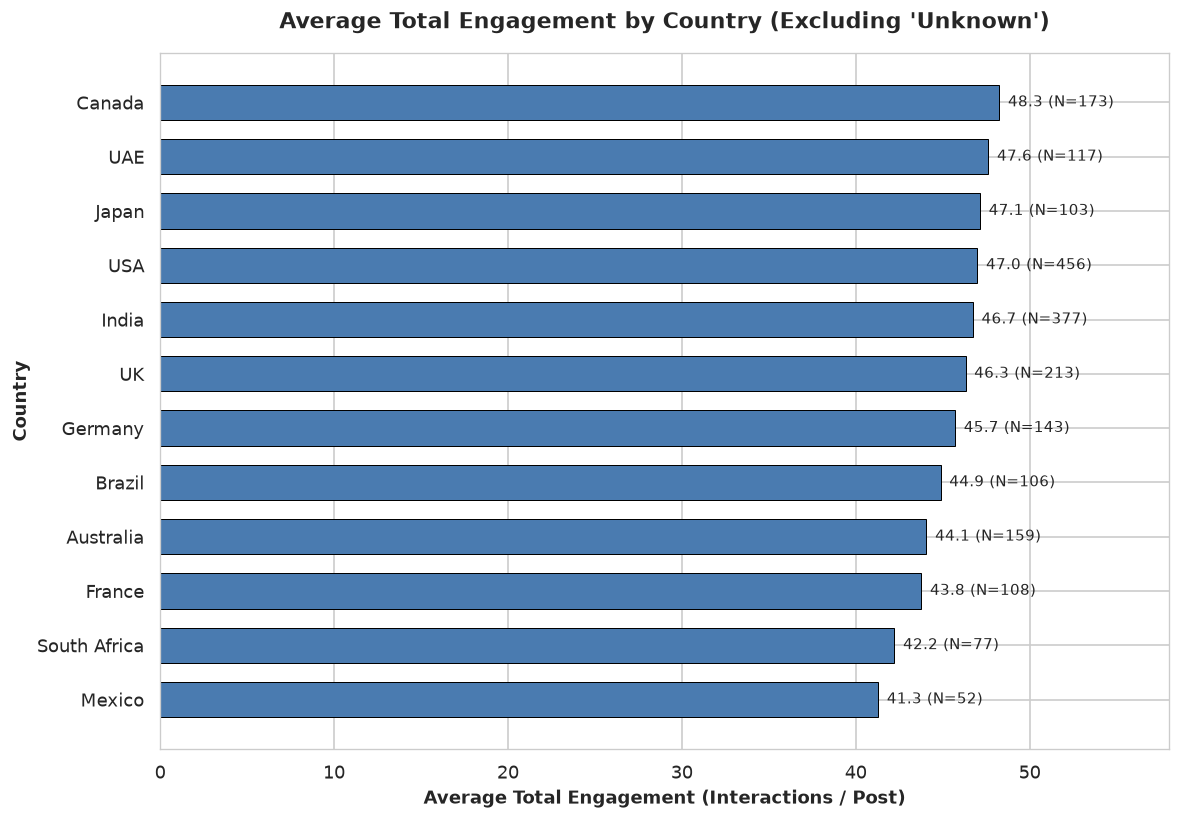

Country Engagement Summary Table (Sorted by Average):
     country  Mean_Engagement  Median_Engagement  Post_Count
      Mexico            41.29               41.5          52
South Africa            42.22               39.0          77
      France            43.77               42.0         108
   Australia            44.06               43.0         159
      Brazil            44.88               39.5         106
     Germany            45.71               42.0         143
          UK            46.31               41.0         213
       India            46.73               42.0         377
         USA            46.99               42.0         456
       Japan            47.15               44.0         103
         UAE            47.62               43.0         117
      Canada            48.25               45.0         173


In [5]:
# 3. Country Comparison Calculation (Excluding 'Unknown')
df_geo = df[df['country'] != 'Unknown']
country_summary = df_geo.groupby('country')['total_engagement'].agg(
    Mean_Engagement='mean',
    Median_Engagement='median',
    Post_Count='count'
).sort_values('Mean_Engagement', ascending=True).reset_index()

print("Country Engagement Summary Table (Sorted by Average):")
print(country_summary.round(2).to_string(index=False))

# Plotting
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(
    country_summary['country'],
    country_summary['Mean_Engagement'],
    color='#4a7bb0',
    height=0.65,
    edgecolor='black',
    linewidth=0.6
)

for bar, count in zip(bars, country_summary['Post_Count']):
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height()/2.,
            f'{w:.1f} (N={count})',
            ha='left', va='center', fontsize=9)

ax.set_title("Average Total Engagement by Country (Excluding 'Unknown')", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Average Total Engagement (Interactions / Post)", fontsize=11, fontweight='bold')
ax.set_ylabel("Country", fontsize=11, fontweight='bold')
ax.set_xlim(0, 58)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "03_country_comparison.png"), dpi=200)
plt.show()


### Interpretation:
1. **Narrow Geographic Variance**: Engagement averages across the 12 nations are remarkably clustered within a tight band between **41.3 interactions per post (Mexico)** and **48.3 interactions per post (Canada)**—a range of only 7.0 interactions.
2. **Top Tier**: Canada (48.3), UAE (47.6), Japan (47.1), USA (47.0), and India (46.7) form the upper cluster.
3. **Geographic vs. Platform Impact**: Geographic origin has far less influence on engagement than platform choice (where the spread between TikTok and LinkedIn is 33.5 interactions).

### Limitations:
* **Sample Size Asymmetry**: USA ($N=456$) and India ($N=377$) represent over 38% of all posts, whereas Mexico has only 52 observations.
* **Sub-national Absence**: Regional, state, and metropolitan drilldowns cannot be conducted due to the lack of sub-national attributes.


## 6. Visualization 4: Longitudinal Monthly Trend (24 Months)
### Research Question:
* **How does average engagement evolve over the 24-month horizon (January 2023 to December 2024)?**

### Visual Encoding & Rationale:
* **Chart Type**: Multi-Point Time-Series Line Chart with Reference Mean Line.
* **Why Appropriate**: Connected line segments effectively communicate continuity, rate of change, and cyclical fluctuations across chronological time intervals.
* **Missing Value Handling**: Monthly averages are computed on valid non-null `total_engagement` records for each respective month.


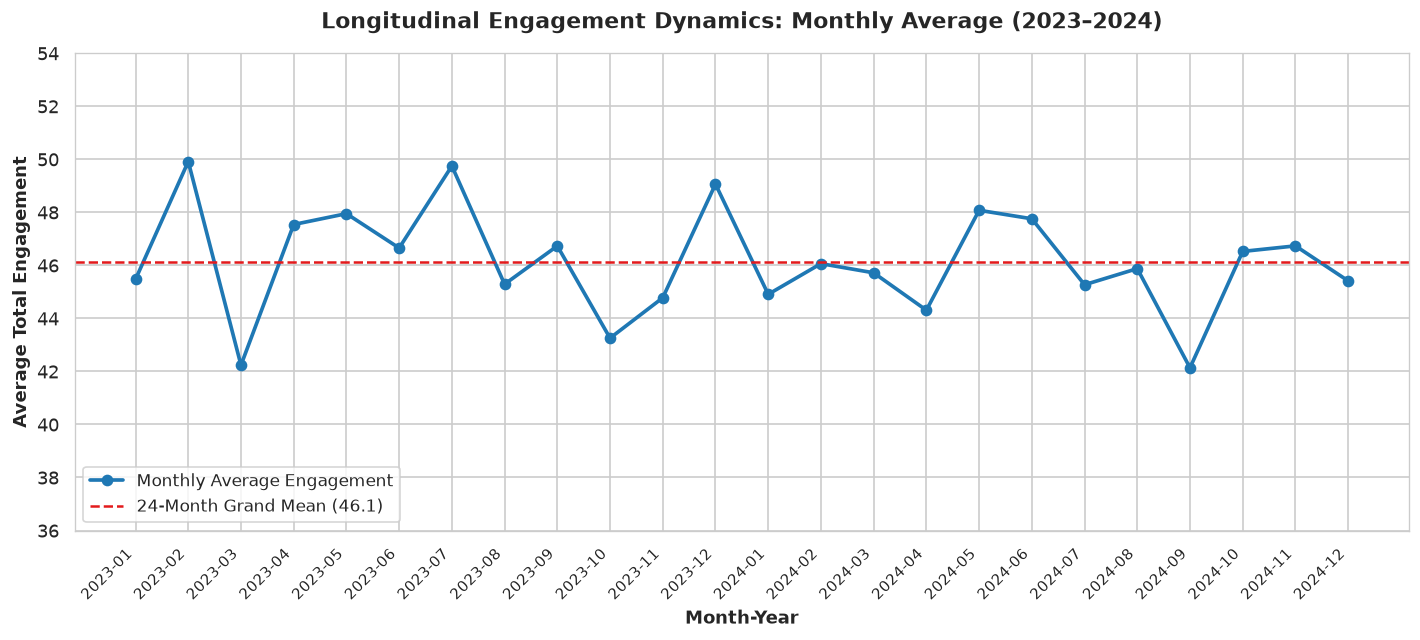

Monthly Trend Summary (First 6 and Last 6 Months):
month_year  Mean_Engagement  Median_Engagement  Post_Count
   2023-01            45.47               42.0          95
   2023-02            49.91               45.5          82
   2023-03            42.24               39.0          76
   2023-04            47.54               42.0          87
   2023-05            47.95               45.0          99
   2023-06            46.65               42.0         101
   2024-07            45.27               44.0          93
   2024-08            45.88               39.0          89
   2024-09            42.14               39.0          81
   2024-10            46.53               41.0          99
   2024-11            46.73               43.0          94
   2024-12            45.41               43.0          87


In [6]:
# 4. Monthly Trend Calculation
monthly_trend = df.groupby('month_year')['total_engagement'].agg(
    Mean_Engagement='mean',
    Median_Engagement='median',
    Post_Count='count'
).reset_index()

grand_mean = df['total_engagement'].mean()

print("Monthly Trend Summary (First 6 and Last 6 Months):")
print(pd.concat([monthly_trend.head(6), monthly_trend.tail(6)]).round(2).to_string(index=False))

# Plotting
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(
    monthly_trend['month_year'],
    monthly_trend['Mean_Engagement'],
    marker='o',
    linewidth=2.2,
    color='#1f78b4',
    markersize=6,
    label='Monthly Average Engagement'
)

ax.axhline(
    grand_mean,
    color='#e31a1c',
    linestyle='--',
    linewidth=1.5,
    label=f'24-Month Grand Mean ({grand_mean:.1f})'
)

ax.set_title("Longitudinal Engagement Dynamics: Monthly Average (2023–2024)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Month-Year", fontsize=11, fontweight='bold')
ax.set_ylabel("Average Total Engagement", fontsize=11, fontweight='bold')
ax.set_xticks(range(len(monthly_trend)))
ax.set_xticklabels(monthly_trend['month_year'], rotation=45, ha='right', fontsize=9)
ax.set_ylim(36, 54)
ax.legend(frameon=True, fontsize=10, loc='lower left')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "04_monthly_trend.png"), dpi=200)
plt.show()


### Interpretation:
1. **Long-Term Equilibrium**: Monthly average engagement remains stable over the two years, oscillating closely around the 24-month grand mean of **46.1 interactions**.
2. **Range of Variation**: Monthly averages reach a high of **49.9** in February 2023 and a low of **42.1** in September 2024.
3. **No Secular Decay or Inflation**: There is no structural upward or downward trend across 2023 and 2024, indicating consistent audience interaction behavior over time.

### Limitations:
* Monthly aggregates pool content across all 5 platforms; small month-to-month fluctuations may reflect minor variations in the monthly platform mix rather than macro behavioral shifts.


## 7. Visualization 5: Sentiment Distribution Across Platforms
### Research Question:
* **How does sentiment classification (Positive, Neutral, Negative) distribute across each social media platform?**

### Visual Encoding & Rationale:
* **Chart Type**: 100% Normalized Stacked Bar Chart with Direct Value Labels.
* **Why Appropriate**: Normalizing to 100% enables fair compositional comparison across platforms of unequal post counts, preventing Twitter's larger sample size from visually dominating.
* **Missing Value Handling**: 33 records with missing sentiment are strictly excluded from cross-tabulation.


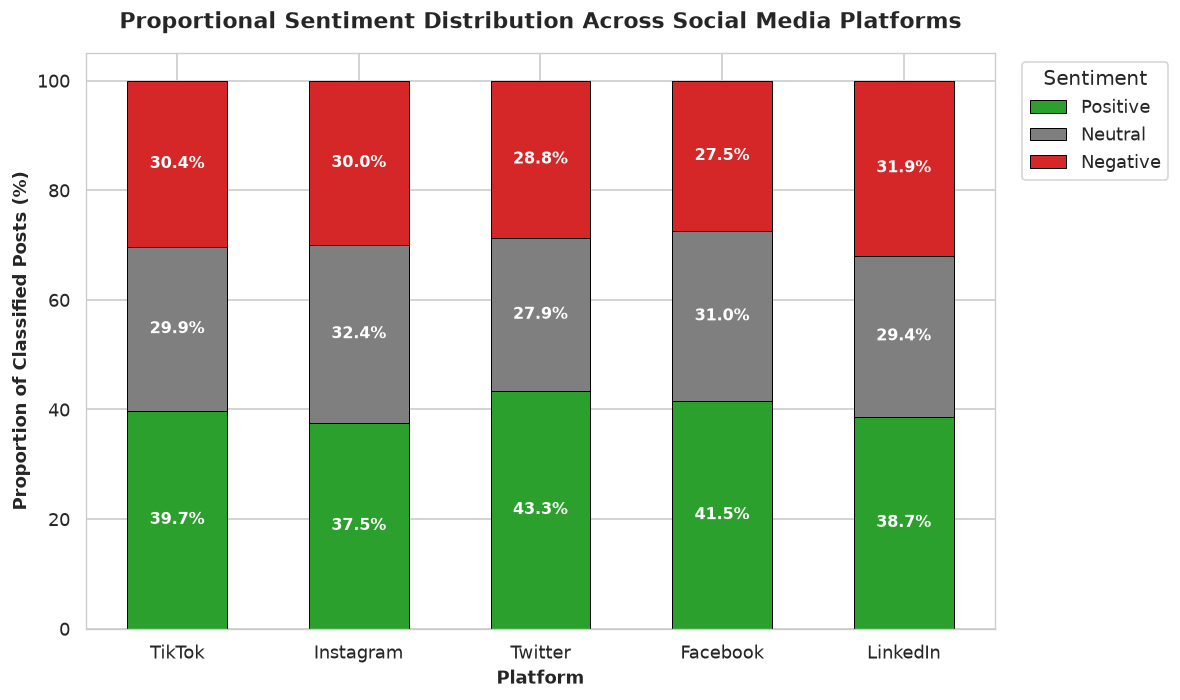

Platform Sentiment Breakdown (Percentage %):
sentiment  Positive  Neutral  Negative
platform                              
TikTok         39.7     29.9      30.4
Instagram      37.5     32.4      30.0
Twitter        43.3     27.9      28.8
Facebook       41.5     31.0      27.5
LinkedIn       38.7     29.4      31.9


In [7]:
# 5. Sentiment Distribution Calculation (Excluding Missing)
df_sent = df[df['sentiment'].notna()]
sent_pct = pd.crosstab(
    df_sent['platform'],
    df_sent['sentiment'],
    normalize='index'
).loc[p_order][['Positive', 'Neutral', 'Negative']] * 100

print("Platform Sentiment Breakdown (Percentage %):")
print(sent_pct.round(1))

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
sent_colors = {'Positive': '#2ca02c', 'Neutral': '#7f7f7f', 'Negative': '#d62728'}
bottom = np.zeros(len(p_order))

for sentiment in ['Positive', 'Neutral', 'Negative']:
    vals = sent_pct[sentiment].values
    bars = ax.bar(
        p_order,
        vals,
        bottom=bottom,
        label=sentiment,
        color=sent_colors[sentiment],
        width=0.55,
        edgecolor='black',
        linewidth=0.6
    )
    for i, (bar, val) in enumerate(zip(bars, vals)):
        ax.text(
            bar.get_x() + bar.get_width()/2.,
            bottom[i] + val/2.,
            f'{val:.1f}%',
            ha='center', va='center',
            color='white', fontweight='bold', fontsize=9.5
        )
    bottom += vals

ax.set_title("Proportional Sentiment Distribution Across Social Media Platforms", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Platform", fontsize=11, fontweight='bold')
ax.set_ylabel("Proportion of Classified Posts (%)", fontsize=11, fontweight='bold')
ax.set_ylim(0, 105)
ax.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "05_sentiment_distribution.png"), dpi=200)
plt.show()


### Interpretation:
1. **Positive Sentiment Dominance**: Positive sentiment constitutes the plurality category across all five platforms: Twitter leads at **43.3%**, followed by Facebook (**41.5%**), TikTok (**39.7%**), LinkedIn (**38.7%**), and Instagram (**37.5%**).
2. **Stable Sentiment Balance**: Despite differing platform cultures, the distribution remains relatively consistent across all networks (~38%–43% Positive, ~28%–32% Neutral, and ~28%–32% Negative).
3. **Negative Sentiment**: Negative posts consistently account for roughly 28% to 32% of content across all platforms (highest on LinkedIn at 31.9%).

### Limitations:
* Sentiment is a broad 3-category classification without sub-tone granularity (e.g. sarcasm, urgency). 33 unclassified posts were excluded.


## 8. Visualization 6: Diurnal Posting Time Analysis (By Hour)
### Research Question:
* **How does average post engagement vary across different hours of the day (00:00 to 23:00)?**

### Visual Encoding & Rationale:
* **Chart Type**: 24-Hour Diurnal Line Chart with Reference Overall Mean.
* **Why Appropriate**: Highlights continuous cyclic temporal variation across the 24-hour cycle.
* **Missing Value Handling**: Hourly averages are computed on valid `total_engagement` records for each respective hour.


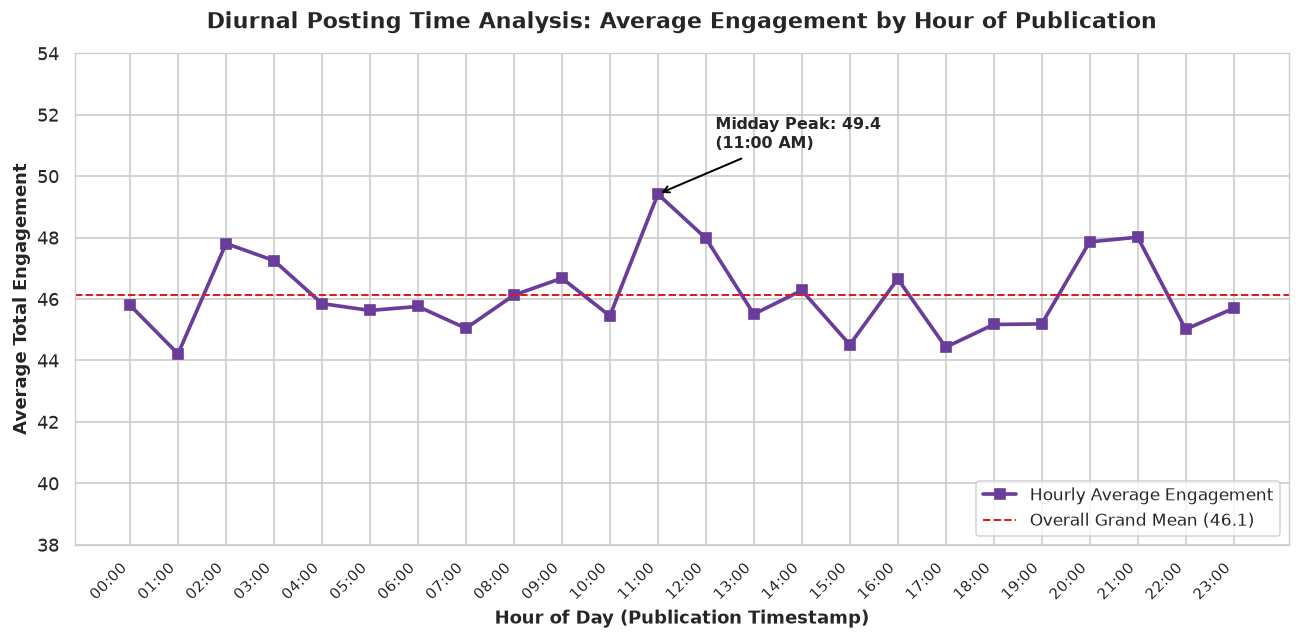

Hourly Posting Time Engagement Table:
 hour  Mean_Engagement  Median_Engagement  Post_Count
    0            45.79               43.0          87
    1            44.21               40.5          80
    2            47.80               44.0          87
    3            47.25               42.0         105
    4            45.85               40.5         112
    5            45.62               41.0          96
    6            45.76               38.0          98
    7            45.04               45.0          91
    8            46.12               42.0          72
    9            46.68               39.0          74
   10            45.45               41.5          96
   11            49.41               43.0          63
   12            47.98               45.5          86
   13            45.50               44.0         101
   14            46.28               43.0          93
   15            44.51               42.5          82
   16            46.65               42.0   

In [8]:
# 6. Hourly Posting Time Calculation
hourly_trend = df.groupby('hour')['total_engagement'].agg(
    Mean_Engagement='mean',
    Median_Engagement='median',
    Post_Count='count'
).reset_index()

print("Hourly Posting Time Engagement Table:")
print(hourly_trend.round(2).to_string(index=False))

# Plotting
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(
    hourly_trend['hour'],
    hourly_trend['Mean_Engagement'],
    marker='s',
    color='#6a3d9a',
    linewidth=2.2,
    markersize=6,
    label='Hourly Average Engagement'
)

ax.axhline(
    grand_mean,
    color='#e31a1c',
    linestyle='--',
    linewidth=1.2,
    label=f'Overall Grand Mean ({grand_mean:.1f})'
)

# Highlight midday peak (11:00)
peak_hour = hourly_trend.loc[hourly_trend['Mean_Engagement'].idxmax()]
ax.annotate(
    f"Midday Peak: {peak_hour['Mean_Engagement']:.1f}\n(11:00 AM)",
    xy=(peak_hour['hour'], peak_hour['Mean_Engagement']),
    xytext=(peak_hour['hour'] + 1.2, peak_hour['Mean_Engagement'] + 1.5),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontweight='bold', fontsize=9.5
)

ax.set_title("Diurnal Posting Time Analysis: Average Engagement by Hour of Publication", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Hour of Day (Publication Timestamp)", fontsize=11, fontweight='bold')
ax.set_ylabel("Average Total Engagement", fontsize=11, fontweight='bold')
ax.set_xticks(range(0, 24))
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=45, ha='right', fontsize=9)
ax.set_ylim(38, 54)
ax.legend(frameon=True, fontsize=10, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "06_hourly_engagement.png"), dpi=200)
plt.show()


### Interpretation:
1. **Midday Peak**: Average engagement peaks at **11:00 AM (49.4 interactions per post)**, followed by elevated engagement at **12:00 PM (48.0)**.
2. **Evening Secondary Peak**: A secondary engagement rise occurs during evening leisure hours between **20:00 (47.9)** and **21:00 (48.0)**.
3. **Early Morning Trough**: The lowest engagement occurs in early morning hours at **01:00 (44.2)**.
4. **Overall Stability**: The diurnal spread is relatively narrow (range of 5.2 interactions between minimum and maximum), indicating active audience consumption around the clock.

### Limitations:
* **Timezone Conflation**: The dataset records timestamps in a single unified timezone without local user offsets; because posts originate across 12 countries, an 11:00 AM timestamp represents different local times for global authors.


## 9. Visualization 7: Overall Total Engagement Distribution
### Research Question:
* **What is the shape and distributional profile of total engagement across social media posts?**

### Visual Encoding & Rationale:
* **Chart Type**: Frequency Histogram with Overlaid Kernel Density Estimation (KDE) and Central Tendency Markers.
* **Why Appropriate**: Histograms reveal skewness, kurtosis, modal density, and the presence of extreme viral outliers in continuous interaction metrics.
* **Missing Value Handling**: Evaluated on the 2,148 valid non-null `total_engagement` records.


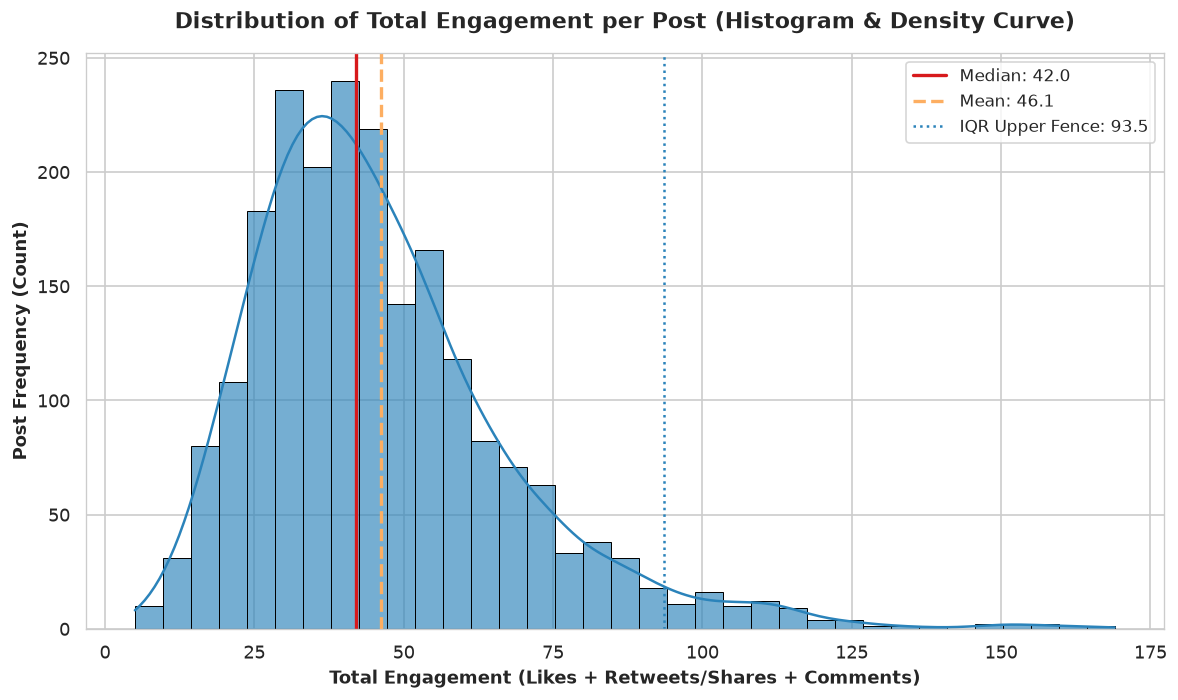

Total Engagement Distributional Statistics:
  Count:       2,148
  Mean:        46.13
  Median:      42.00
  Std Dev:     21.75
  Skewness:    1.35 (Positive right-skew)
  Q1:          31.00 | Q3: 56.00 | IQR: 25.00
  Upper Fence: 93.50 (Outliers: 81 posts)
  Min / Max:   5.00 / 169.00


In [9]:
# 7. Engagement Distribution Calculation
te = df['total_engagement'].dropna()
te_mean = te.mean()
te_median = te.median()
te_std = te.std()
te_skew = te.skew()
q1 = te.quantile(0.25)
q3 = te.quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print("Total Engagement Distributional Statistics:")
print(f"  Count:       {len(te):,}")
print(f"  Mean:        {te_mean:.2f}")
print(f"  Median:      {te_median:.2f}")
print(f"  Std Dev:     {te_std:.2f}")
print(f"  Skewness:    {te_skew:.2f} (Positive right-skew)")
print(f"  Q1:          {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"  Upper Fence: {upper_fence:.2f} (Outliers: {(te > upper_fence).sum()} posts)")
print(f"  Min / Max:   {te.min():.2f} / {te.max():.2f}")

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(te, bins=35, kde=True, color='#2b83ba', edgecolor='black', linewidth=0.6, alpha=0.65, ax=ax)

ax.axvline(te_median, color='#d7191c', linestyle='-', linewidth=2, label=f'Median: {te_median:.1f}')
ax.axvline(te_mean, color='#fdae61', linestyle='--', linewidth=2, label=f'Mean: {te_mean:.1f}')
ax.axvline(upper_fence, color='#2b83ba', linestyle=':', linewidth=1.5, label=f'IQR Upper Fence: {upper_fence:.1f}')

ax.set_title("Distribution of Total Engagement per Post (Histogram & Density Curve)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Total Engagement (Likes + Retweets/Shares + Comments)", fontsize=11, fontweight='bold')
ax.set_ylabel("Post Frequency (Count)", fontsize=11, fontweight='bold')
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "07_engagement_distribution.png"), dpi=200)
plt.show()


### Interpretation:
1. **Right-Skewed Distribution**: The distribution exhibits pronounced positive skewness (**+1.35**), characteristic of power-law dynamics in social network engagement.
2. **Mean vs. Median Divergence**: The arithmetic mean (**46.1**) is substantially higher than the median (**42.0**), pulled upward by high-performing viral content.
3. **Interquartile Range**: 50% of all posts generate between **31.0 and 56.0 interactions**.
4. **Outlier Tail**: Exactly **81 posts (3.8%)** lie beyond the upper IQR fence ($>93.5$), stretching up to a dataset maximum of **169 interactions**.

### Limitations:
* 52 records with incomplete like or comment fields were omitted from the distribution.


## 10. Analytical Investigation: Follower-Based Engagement Rate & Limitations
### Definition & Formula:
$$\text{engagement\_rate\_per\_follower} = \left(\frac{\text{total\_engagement}}{\text{followers\_count}}\right) \times 100$$

### Critical Analytical Limitations:
1. **Impression vs. Follower Mismatch**: In modern recommendation algorithms (TikTok FYP, Instagram Explore, Twitter For You), content is distributed primarily by interest rather than social graph. An author's follower count is an imperfect proxy for scale, not actual reach.
2. **Small-Denominator Inflation**: Creators with small followings (e.g. 20–50 followers) produce extreme engagement rates (e.g. 100%–250%) from modest interaction numbers, severely skewing arithmetic means.
3. **Data Missingness**: Evaluated strictly on 2,064 records where both total engagement and follower counts were valid and $>0$ (136 records excluded).


In [10]:
# 8. Follower-Based Engagement Rate Distribution Analysis
er = df['engagement_rate_per_follower'].dropna()

print("Engagement Rate per Follower (%) Summary Statistics:")
print(f"  Count:       {len(er):,}")
print(f"  Mean:        {er.mean():.2f}%")
print(f"  Median:      {er.median():.2f}%")
print(f"  IQR:         {er.quantile(0.75) - er.quantile(0.25):.2f}% (Q1: {er.quantile(0.25):.2f}%, Q3: {er.quantile(0.75):.2f}%)")
print(f"  Min / Max:   {er.min():.4f}% / {er.max():.2f}%")
print(f"  Rates > 50%: {(er > 50).sum()} posts ({(er > 50).mean()*100:.1f}%)")
print(f"  Rates >100%: {(er > 100).sum()} posts ({(er > 100).mean()*100:.1f}%)")

# Comparison across platforms
er_by_p = df.groupby('platform')['engagement_rate_per_follower'].agg(
    Median_Rate=('median'),
    Mean_Rate=('mean'),
    Count=('count')
).loc[p_order].reset_index()

print("\nEngagement Rate per Follower by Platform:")
print(er_by_p.round(2).to_string(index=False))


Engagement Rate per Follower (%) Summary Statistics:
  Count:       2,064
  Mean:        6.62%
  Median:      2.34%
  IQR:         5.69% (Q1: 0.84%, Q3: 6.53%)
  Min / Max:   0.0166% / 250.00%
  Rates > 50%: 31 posts (1.5%)
  Rates >100%: 11 posts (0.5%)

Engagement Rate per Follower by Platform:
 platform  Median_Rate  Mean_Rate  Count
   TikTok         3.46       9.75    371
Instagram         2.87       7.15    549
  Twitter         2.11       6.21    681
 Facebook         1.61       4.16    354
 LinkedIn         1.22       3.92    109


### Analytical Conclusion on Follower-Based Engagement Rate:
Due to heavy denominator distortion on micro-accounts (producing rates up to 250%) and the lack of true impression reach data, **total engagement** is the primary, reliable metric for cross-platform and geographic comparisons. Follower-based rates should be interpreted cautiously as creator-efficiency indicators rather than absolute performance metrics.


## 11. Milestone 3 Summary & Key Findings Matrix

| Visualization | Primary Metric | Top Finding | Key Analytical Caveat |
|:---|:---|:---|:---|
| **1. Platform Comparison** | Average Total Engagement | **TikTok leads (60.3)**, followed by Instagram (50.2), Twitter (43.4), Facebook (36.2), LinkedIn (26.8). | Substantial sample size disparity between Twitter ($N=712$) and LinkedIn ($N=116$). |
| **2. Engagement Components** | Likes, Shares, Comments | **Likes dominate (>75%)** across all networks. Shares consistently outnumber comments ~2:1. | Comments carry higher friction and qualitative depth than simple likes. |
| **3. Country Comparison** | Average Total Engagement | **Narrow geographic variance** (41.3 to 48.3). Canada (48.3) and UAE (47.6) lead slightly. | Country sample sizes vary heavily (USA $N=456$ vs Mexico $N=52$). 'Unknown' (66 posts) excluded. |
| **4. Monthly Trend** | Monthly Average Engagement | **Longitudinal equilibrium** across 24 months, oscillating tightly around grand mean (46.1). | Minor monthly oscillations driven by shifting platform mixes. |
| **5. Sentiment Distribution** | Proportional Breakdown | **Positive sentiment is plurality** across all platforms (37.5% to 43.3%). Negative sentiment is steady (~28%–32%). | High-level 3-class classification without aspect-level depth. |
| **6. Posting Time Analysis** | Hourly Average Engagement | **Midday peak at 11:00 AM (49.4)** with secondary evening lift at 20:00–21:00 (48.0). | Timestamps reflect a single unified timezone rather than local audience time. |
| **7. Engagement Distribution** | Histogram & Density | **Right-skewed distribution (+1.35)** with median (42.0) below mean (46.1). 81 viral outliers. | High viral values are authentic and retained. |

> **Milestone Status**: Exploratory visualization complete. Pre-rendered figures saved to `reports/figures/`. Ready for stakeholder review prior to Milestone 4 dashboard design.
